# Open Pool EDA

数据：[crtproduction/name-that-llm-open-pool](https://www.kaggle.com/datasets/crtproduction/name-that-llm-open-pool)，本地路径 `assets/external/open_pool/`。版本以下载时为准，作者的 removal 记录写到 v15。

问题：
1. 规模与构成：每个 label、来源、推理设置各有多少条？
2. 和官方 train 的分布差异：长度、排版、文体。
3. 训练集里看到的排版硬规则（Claude/GLM 不用 `’`、Gemini 不用 `—`）在 pool 里是否成立？
4. **迁移**：只用 pool 训练，在全部 2,699 条真实 train 上评估，效果如何？数据量曲线是什么样？pool 加上真实数据能比只用真实数据好多少？

In [1]:
import re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score, recall_score
from scipy.sparse import hstack, vstack

ROOT = Path.cwd()
while not (ROOT / 'assets/data/train.csv').exists():
    ROOT = ROOT.parent
POOL = ROOT / 'assets/external/open_pool'
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.precision', 3, 'display.max_colwidth', 60)
sns.set_theme(style='whitegrid', font_scale=0.85)

FAMILY = {'gpt-5.5':'OpenAI','gpt-5.6-luna':'OpenAI','gpt-5.6-sol':'OpenAI','gpt-5.6-terra':'OpenAI','gpt-6-astra':'OpenAI',
          'gemini-3.1-pro-preview':'Google','gemini-3.6-flash':'Google','gemini-3.7-flash':'Google','gemini-3.8-flash':'Google',
          'claude-fable-5':'Anthropic','claude-opus-4-6':'Anthropic','claude-opus-4-8':'Anthropic','claude-opus-5':'Anthropic','claude-sonnet-5':'Anthropic',
          'qwen3.8-max':'Qwen','glm-5.3':'ZAI','glm-5.3-flash':'ZAI','kimi-k3':'Moonshot'}
ORDER = list(FAMILY)

tr = pd.read_csv(ROOT / 'assets/data/train.csv')
pool = pd.read_parquet(POOL / 'ntl_open_pool.parquet')
for d in (tr, pool):
    for c in d.columns:
        if d[c].dtype == 'string' or str(d[c].dtype) == 'str':
            d[c] = d[c].astype(object)
print('train', tr.shape, '| pool', pool.shape)

train (2699, 4) | pool (226191, 30)


## 1. 规模与构成

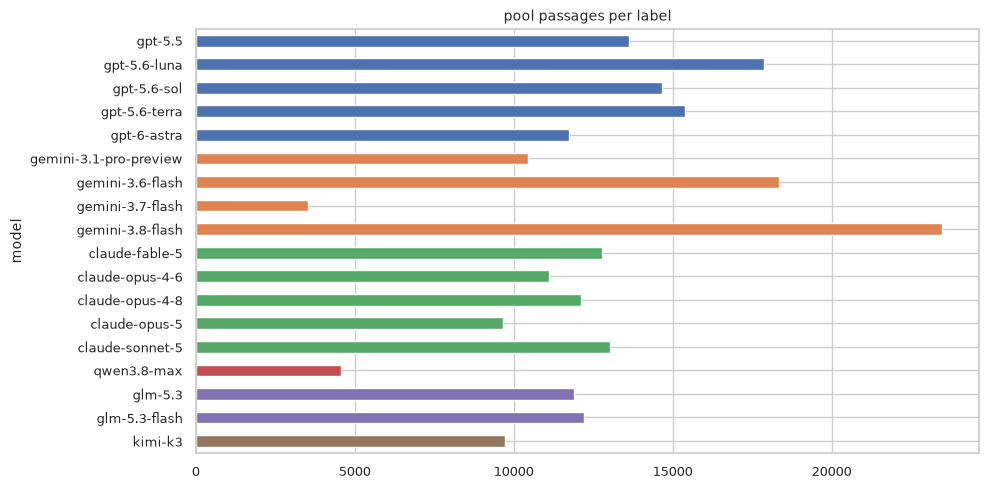

最多 / 最少: 23474 / 3541 （6.6x）


In [2]:
cnt = pool.model.value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(10, 5))
cnt.plot.barh(ax=ax, color=[sns.color_palette()[list(dict.fromkeys(FAMILY.values())).index(FAMILY[m])] for m in ORDER])
ax.invert_yaxis(); ax.set_title('pool passages per label'); plt.tight_layout(); plt.show()
print('最多 / 最少:', cnt.max(), '/', cnt.min(), f'（{cnt.max()/cnt.min():.1f}x）')

In [3]:
# 来源 × label：每个 label 的数据由几个来源撑起来？最大来源占比多少？
st = pool.groupby(['model', 'source_dataset']).size()
summ = pd.DataFrame({
    'n': cnt,
    'n_sources': st.groupby(level=0).size(),
    'top_source_share': st.groupby(level=0).apply(lambda s: s.max() / s.sum()),
    'top_source': st.groupby(level=0).idxmax().map(lambda t: t[1]),
    'kb_proxy': pool.groupby('model').flag_kb_proxy.mean(),
    'served_model_known': pool.assign(k=pool.gen_served_model.ne('')).groupby('model').k.mean(),
}).loc[ORDER]
summ

,n,n_sources,top_source_share,top_source,kb_proxy,served_model_known
model,,,,,,
gpt-5.5,13637,48,0.140,trnhip/ntl-api-gen,0.532,0.455
gpt-5.6-luna,17870,51,0.122,abdullah1afify/ntl-generations,0.581,0.491
gpt-5.6-sol,14679,50,0.135,trnhip/ntl-api-gen,0.535,0.453
gpt-5.6-terra,15382,51,0.121,trnhip/ntl-api-gen,0.543,0.458
gpt-6-astra,11737,47,0.164,trnhip/ntl-api-gen,0.487,0.416
gemini-3.1-pro-preview,10439,41,0.301,harshitkmr/ntl-google-gen-v1,0.378,0.254
gemini-3.6-flash,18357,48,0.397,harshitkmr/ntl-google-gen-v1,0.280,0.250
gemini-3.7-flash,3541,5,0.567,davidpiln/ntl-vertex-gemini-gen,0.000,0.433
gemini-3.8-flash,23474,54,0.314,harshitkmr/ntl-google-gen-v1,0.293,0.292


In [4]:
# 推理设置分布（行归一化）
pd.crosstab(pool.model, pool.gen_reasoning, normalize='index').loc[ORDER].round(2)

gen_reasoning,default,high,low,medium,minimal,off,other,unknown
model,,,,,,,,
gpt-5.5,0.48,0.00,0.16,0.00,0.00,0.00,0.00,0.36
gpt-5.6-luna,0.56,0.00,0.12,0.00,0.00,0.01,0.01,0.31
gpt-5.6-sol,0.55,0.00,0.12,0.00,0.00,0.00,0.00,0.33
gpt-5.6-terra,0.56,0.00,0.12,0.00,0.00,0.01,0.00,0.31
gpt-6-astra,0.45,0.00,0.16,0.00,0.00,0.00,0.00,0.39
gemini-3.1-pro-preview,0.29,0.00,0.16,0.00,0.00,0.00,0.00,0.55
gemini-3.6-flash,0.23,0.02,0.11,0.00,0.00,0.00,0.00,0.64
gemini-3.7-flash,0.91,0.00,0.01,0.00,0.00,0.01,0.08,0.00
gemini-3.8-flash,0.40,0.02,0.04,0.03,0.00,0.00,0.01,0.51


In [5]:
# 同一段文本被多个数据集收录（社区数据互相转载）
print('n_sources 分布（该文本出现在几个源数据集里）:')
print(pool.n_sources.clip(upper=10).value_counts().sort_index().to_dict())
print('完全相同文本的重复行:', pool.text.duplicated().sum())

n_sources 分布（该文本出现在几个源数据集里）:
{1: 99369, 2: 19227, 3: 12718, 4: 18742, 5: 19937, 6: 4157, 7: 6624, 8: 12786, 9: 797, 10: 31834}


完全相同文本的重复行: 0


## 2. prompt 结构

In [6]:
prompts = pd.read_parquet(POOL / 'prompts.parquet')
print('prompt_canon 数:', pool.prompt_canon.nunique(), '| prompts.parquet:', len(prompts))
print('prompt_evidence:', pool.prompt_evidence.value_counts().to_dict())
pp = pool.groupby('prompt_canon').agg(n=('id', 'size'), labels=('model', 'nunique'))
print('每个 prompt 的篇数:', pp.n.describe()[['mean', '50%', 'max']].to_dict())
print('每个 prompt 覆盖的 label 数:', pp.labels.value_counts().sort_index().to_dict())
print('与 train prompt 接近的行:', pool.flag_near_train_prompt.sum(), '| max_cos_train 99 分位:', pool.max_cos_train.quantile(.99).round(3))
prompts.sample(8, random_state=0)[['prompt_text', 'panel_labels', 'passages']]

prompt_canon 数: 36069 | prompts.parquet: 17671
prompt_evidence: {'own_bank': 75924, 'own_text': 65109, 'id_only': 42265, 'other_text': 27191, 'centroid': 14169, 'none': 1533}
每个 prompt 的篇数: {'mean': 6.271063794394078, '50%': 2.0, 'max': 1533.0}
每个 prompt 覆盖的 label 数: {1: 10729, 2: 7939, 3: 3308, 4: 2422, 5: 1963, 6: 473, 7: 368, 8: 730, 9: 1481, 10: 553, 11: 819, 12: 897, 13: 592, 14: 427, 15: 506, 16: 846, 17: 1302, 18: 714}
与 train prompt 接近的行: 0 | max_cos_train 99 分位: 0.258


,prompt_text,panel_labels,passages
5056,Explain how Leonhard Euler solved the Seven Bridges of K...,11,11
13543,"Write a vivid passage describing the Local Bubble, the l...",2,2
15256,"Write a vivid, slightly visceral description of autohemo...",2,2
9750,Give a concise account of earthquake prediction. Keep it...,5,5
13134,"Explain the Poincaré recurrence theorem, which states th...",3,3
8645,Describe the concept of Hawking radiation in a haunting ...,6,6
10893,Open with a concrete example. What should a curious read...,4,4
11489,Open with a concrete example. Explain the debate around ...,4,4


## 3. 长度对比

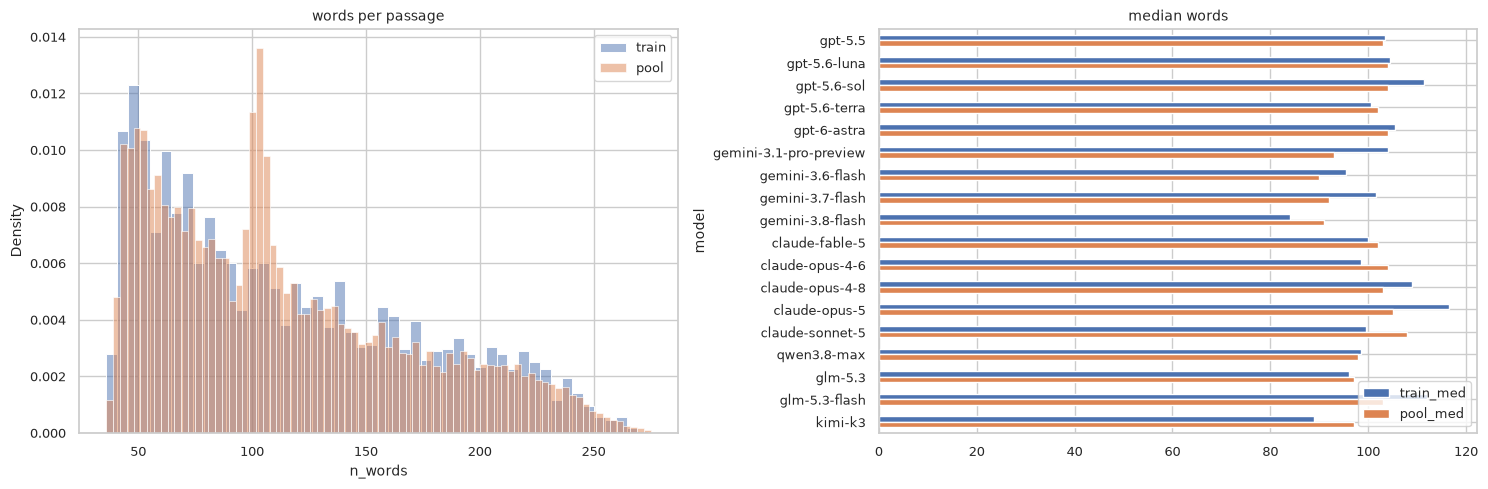

,train_med,pool_med,"pool_out_of_[36,274]"
model,,,
gpt-5.5,103.5,103.0,0.000e+00
gpt-5.6-luna,104.5,104.0,5.596e-05
gpt-5.6-sol,111.5,104.0,0.000e+00
gpt-5.6-terra,100.5,102.0,0.000e+00
gpt-6-astra,105.5,104.0,8.520e-05
gemini-3.1-pro-preview,104.0,93.0,0.000e+00
gemini-3.6-flash,95.5,90.0,0.000e+00
gemini-3.7-flash,101.5,92.0,0.000e+00
gemini-3.8-flash,84.0,91.0,0.000e+00


In [7]:
tr['n_words'] = tr.text.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(tr.n_words, bins=50, stat='density', ax=ax[0], label='train', alpha=.5)
sns.histplot(pool.n_words.clip(upper=400), bins=80, stat='density', ax=ax[0], label='pool', alpha=.5, color='C1')
ax[0].legend(); ax[0].set_title('words per passage')
cmp = pd.DataFrame({'train_med': tr.groupby('model').n_words.median(), 'pool_med': pool.groupby('model').n_words.median(),
                    'pool_out_of_[36,274]': pool.groupby('model').n_words.apply(lambda s: ((s < 36) | (s > 274)).mean())}).loc[ORDER]
cmp[['train_med', 'pool_med']].plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title('median words')
plt.tight_layout(); plt.show()
cmp

## 4. 排版与文体：pool vs train

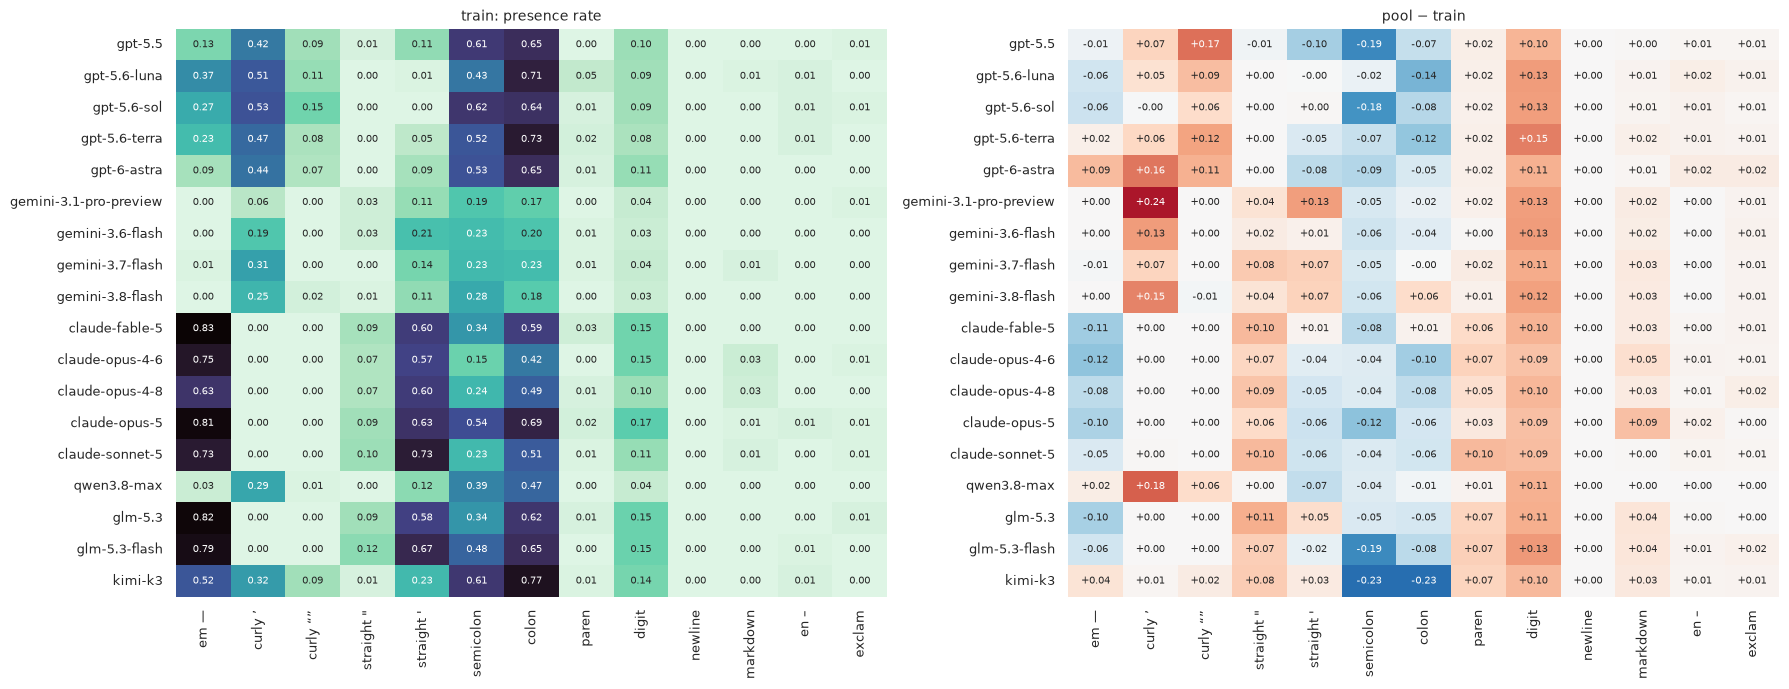

In [8]:
MARK = {'em —': '—', 'curly ’': '’', 'curly “”': '[“”]', 'straight "': '"', 'straight \'': "'", 'semicolon': ';', 'colon': ':',
        'paren': r'\(', 'digit': r'\d', 'newline': '\n', 'markdown': r'[*#`]|^\s*- ', 'en –': '–', 'exclam': '!'}
def presence(df):
    return pd.DataFrame({k: df.text.str.contains(v, regex=True) for k, v in MARK.items()}).groupby(df.model.values).mean().loc[ORDER]
P_tr, P_pool = presence(tr), presence(pool)
diff = P_pool - P_tr
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(P_tr, annot=True, fmt='.2f', cmap='mako_r', cbar=False, ax=ax[0], annot_kws={'size': 7}); ax[0].set_title('train: presence rate')
sns.heatmap(diff, annot=True, fmt='+.2f', cmap='RdBu_r', center=0, vmin=-.3, vmax=.3, cbar=False, ax=ax[1], annot_kws={'size': 7}); ax[1].set_title('pool − train')
plt.tight_layout(); plt.show()

In [9]:
# 训练集里出现率为 0 的硬规则，在 pool 里被违反的比例，以及违反集中在哪些来源
RULES = [('curly ’', '’', [m for m in ORDER if FAMILY[m] in ('Anthropic', 'ZAI')]),
         ('curly “”', '[“”]', [m for m in ORDER if FAMILY[m] in ('Anthropic', 'ZAI')] + ['gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash']),
         ('em —', '—', ['gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.8-flash'])]
rows = []
for name, pat, models in RULES:
    sub = pool[pool.model.isin(models)]
    hit = sub.text.str.contains(pat, regex=True)
    tr_hit = tr[tr.model.isin(models)].text.str.contains(pat, regex=True)
    top = sub[hit].source_dataset.value_counts().head(3)
    rows.append(dict(rule=f'{name} ∉ {len(models)} labels', train_viol=tr_hit.mean(), pool_viol=hit.mean(), pool_n=len(sub),
                     top_sources=', '.join(f'{k.split("/")[-1]}:{v}' for k, v in top.items())))
pd.DataFrame(rows)

,rule,train_viol,pool_viol,pool_n,top_sources
0,curly ’ ∉ 7 labels,0.0,6.765e-04,82778,"ntl-claude-family-passages:35, ntl-own-exact-route-gener..."
1,curly “” ∉ 10 labels,0.0,4.778e-04,115115,"ntl-free-proxy-generations:13, ntl-panel-gap-passages-ka..."
2,em — ∉ 3 labels,0.0,0.000e+00,52270,


In [10]:
# Gemini 的 em dash：pool 中哪些来源保留了 em dash（注意 adurey 来源把 Gemini 的 em dash 替换成了逗号）
g = pool[pool.model.str.startswith('gemini')]
(g.assign(em=g.text.str.contains('—')).groupby('source_dataset').em.agg(['mean', 'size'])
  .query('size >= 200').sort_values('mean', ascending=False).head(12))

,mean,size
source_dataset,,
abdullah1afify/ntl-generations,0.0,1236
abhinavsaipodugu/ntl-proxy-gpt-gemini-passages,0.0,1403
adurey/ntl-proxy-gen-20261031,0.0,764
alessandrolair/ntl-kaggle-benchmarks-generated-passages,0.0,844
alperen5252525/ntl-public-passage-pool-v1,0.0,215
alperen5252525/ntl-vertex-gemini-proxy-gpt-generations,0.0,2573
aniruduh9/ntl-hard-supplement,0.0,279
arxitekton/ntl-claude-gen-v1,0.0,799
asiralabi/ntl-src,0.0,260


In [11]:
# 文体量对比：每句词数、第一/二人称、是否以标点结尾
def stylo(df):
    t = df.text
    n_s = t.str.count(r'[.!?](\s|$)').clip(lower=1)
    lw = t.str.lower()
    return pd.DataFrame({'words_per_sent': df.text.str.split().str.len() / n_s,
                         'we_our': lw.str.contains(r'\b(?:we|our|us)\b'), 'i_me_my': lw.str.contains(r'\b(?:i|me|my)\b'),
                         'you': lw.str.contains(r'\byour?\b'), 'ends_punct': t.str.strip().str[-1].isin(list('.!?"”’'))}
                       ).groupby(df.model.values).mean().loc[ORDER]
S_tr, S_pool = stylo(tr), stylo(pool)
pd.concat({'train': S_tr, 'pool': S_pool}, axis=1).swaplevel(axis=1).sort_index(axis=1).round(3)

ends_punct        i_me_my        we_our        words_per_sent            you       
                             pool  train    pool  train   pool  train           pool   train   pool  train
gpt-5.5                     1.000  1.000   0.080  0.107  0.139  0.293         21.966  26.348  0.137  0.140
gpt-5.6-luna                1.000  1.000   0.074  0.080  0.131  0.273         19.676  23.685  0.118  0.087
gpt-5.6-sol                 1.000  1.000   0.073  0.107  0.129  0.260         19.556  25.258  0.112  0.073
gpt-5.6-terra               1.000  1.000   0.066  0.060  0.117  0.207         21.359  26.264  0.107  0.073
gpt-6-astra                 1.000  1.000   0.073  0.080  0.157  0.353         18.361  21.190  0.175  0.187
gemini-3.1-pro-preview      1.000  1.000   0.057  0.073  0.175  0.420         19.964  20.259  0.160  0.147
gemini-3.6-flash            1.000  1.000   0.046  0.060  0.126  0.313         21.516  24.655  0.111  0.147
gemini-3.7-flash            1.000  1.000   0.045  0.053  0.146  0.307         22.394  23.874  0.110  0.147
gemini-3.8-flash            1.000  1.000   0.039  0.033  0.129  0.273         21.767  22.728  0.122  0.147
claude-fable-5              1.000  1.000   0.045  0.040  0.164  0.289         23.190  24.125  0.190  0.181
claude-opus-4-6             1.000  1.000   0.050  0.040  0.154  0.320         25.881  27.240  0.187  0.193
claude-opus-4-8             1.000  1.000   0.062  0.067  0.196  0.373         23.875  23.940  0.233  0.240
claude-opus-5               0.999  1.000   0.068  0.067  0.144  0.320         22.969  23.834  0.247  0.240
claude-sonnet-5             1.000  1.000   0.056  0.060  0.148  0.280         26.858  26.208  0.175  0.133
qwen3.8-max                 1.000  1.000   0.051  0.067  0.145  0.300         21.384  22.220  0.135  0.133
glm-5.3                     1.000  1.000   0.076  0.080  0.181  0.300         23.723  23.338  0.191  0.207
glm-5.3-flash               1.000  1.000   0.070  0.067  0.183  0.373         23.172  23.226  0.196  0.193
kimi-k3                     0.991  0.987   0.071  0.080  0.165  0.267         22.013  25.772  0.161  0.160

## 5. 迁移实验

固定特征和模型：char_wb(1–4) + word(1–2) TF-IDF，`LinearSVC(C=0.3)`。
- **real-only**：在真实 train 上做 5 折分组 CV（按 prompt 分组）。
- **pool-only**：只用 pool 训练，每个 label 最多取 N 条，在全部 2,699 条真实 train 上评估。pool 的 prompt 和 train 不重合（`flag_near_train_prompt` 全为 False）。
- **pool + real**：与 real-only 用相同的 5 折，训练折里加入 pool。

所有 TF-IDF 都只在当次训练集上 fit。

In [12]:
import time
VEC = [dict(analyzer='char_wb', ngram_range=(1, 4), max_features=300_000, min_df=3),
       dict(analyzer='word', ngram_range=(1, 2), max_features=200_000, min_df=2, token_pattern=r'(?u)\b\w+\b|[^\w\s]')]
def fit_predict(train_text, train_y, test_text):
    vs = [TfidfVectorizer(sublinear_tf=True, lowercase=False, dtype=np.float32, **c) for c in VEC]
    Xt = hstack([v.fit_transform(train_text) for v in vs]).tocsr()
    Xv = hstack([v.transform(test_text) for v in vs]).tocsr()
    clf = LinearSVC(C=0.3, class_weight='balanced').fit(Xt, train_y)
    return clf.predict(Xv)

y = tr.model.to_numpy(dtype=object)
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(tr, y, groups=tr.prompt_id))
def sample_pool(n, df=pool, seed=0):
    return df.sample(frac=1, random_state=seed).groupby('model').head(n)

results, recalls = {}, {}
t0 = time.time()
pred = np.empty(len(tr), dtype=object)
for trn, val in folds:
    pred[val] = fit_predict(tr.text.iloc[trn], y[trn], tr.text.iloc[val])
results['real-only (CV)'] = balanced_accuracy_score(y, pred); recalls['real-only'] = pred
print('real-only', round(results['real-only (CV)'], 4), f'{time.time()-t0:.0f}s')

real-only 0.333 20s


N=  150  rows=  2700  bal_acc=0.2582  (7s)


N=  500  rows=  9000  bal_acc=0.3390  (17s)


N= 1000  rows= 18000  bal_acc=0.3834  (30s)


N= 2000  rows= 36000  bal_acc=0.4186  (57s)


N= 4000  rows= 71541  bal_acc=0.4597  (113s)


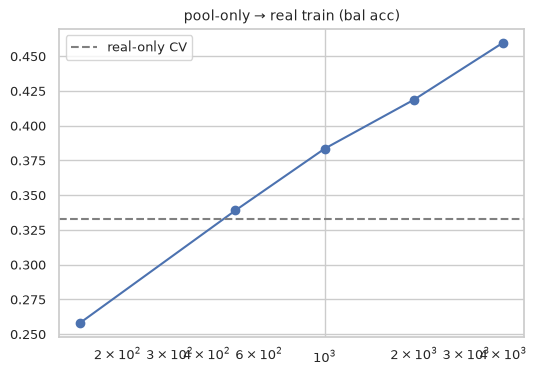

In [13]:
# 数据量曲线：pool-only，每个 label 取 N 条
curve = {}
for n in [150, 500, 1000, 2000, 4000]:
    t0 = time.time()
    s = sample_pool(n)
    p = fit_predict(s.text, s.model, tr.text)
    curve[n] = balanced_accuracy_score(y, p)
    if n == 4000: recalls['pool-only 4000'] = p
    print(f'N={n:5d}  rows={len(s):6d}  bal_acc={curve[n]:.4f}  ({time.time()-t0:.0f}s)')
results.update({f'pool-only N={n}': v for n, v in curve.items()})
ax = pd.Series(curve).plot(marker='o', logx=True, figsize=(6, 4), title='pool-only → real train (bal acc)')
ax.axhline(results['real-only (CV)'], ls='--', c='gray', label='real-only CV'); ax.legend(); plt.show()

In [14]:
# 过滤策略对比（每个 label N=2000，固定 seed）
N = 2000
variants = {
    'all': pool,
    'no kb_proxy': pool[~pool.flag_kb_proxy],
    'kimi: only reasoning=high': pool[(pool.model != 'kimi-k3') | (pool.gen_reasoning == 'high')],
    'style_score top 50% per label': pool[pool.style_score >= pool.groupby('model').style_score.transform('median')],
    'n_sources == 1 (no reshare)': pool[pool.n_sources == 1],
}
for name, df in variants.items():
    t0 = time.time()
    s = sample_pool(N, df)
    p = fit_predict(s.text, s.model, tr.text)
    results[f'pool N={N} | {name}'] = balanced_accuracy_score(y, p)
    print(f'{name:35s} rows={len(s):6d} min/label={s.model.value_counts().min():5d}  bal_acc={results[f"pool N={N} | {name}"]:.4f}  ({time.time()-t0:.0f}s)')

all                                 rows= 36000 min/label= 2000  bal_acc=0.4186  (57s)


no kb_proxy                         rows= 36000 min/label= 2000  bal_acc=0.4164  (57s)


kimi: only reasoning=high           rows= 36000 min/label= 2000  bal_acc=0.4382  (56s)


style_score top 50% per label       rows= 35772 min/label= 1772  bal_acc=0.4278  (52s)


n_sources == 1 (no reshare)         rows= 34703 min/label=  703  bal_acc=0.4038  (52s)


In [15]:
# pool + real：在与 real-only 相同的 5 折上，训练折加入 pool（每个 label 4000 条）
s = sample_pool(4000)
pred = np.empty(len(tr), dtype=object)
for trn, val in folds:
    pred[val] = fit_predict(pd.concat([tr.text.iloc[trn], s.text]), np.concatenate([y[trn], s.model.values]), tr.text.iloc[val])
results['pool 4000 + real (CV)'] = balanced_accuracy_score(y, pred); recalls['pool+real'] = pred
pd.Series(results, name='balanced_accuracy').round(4).to_frame()

,balanced_accuracy
real-only (CV),0.333
pool-only N=150,0.258
pool-only N=500,0.339
pool-only N=1000,0.383
pool-only N=2000,0.419
pool-only N=4000,0.460
pool N=2000 | all,0.419
pool N=2000 | no kb_proxy,0.416
pool N=2000 | kimi: only reasoning=high,0.438
pool N=2000 | style_score top 50% per label,0.428


In [16]:
rec = pd.DataFrame({k: recall_score(y, p, labels=ORDER, average=None) for k, p in recalls.items()}, index=ORDER)
rec['Δ pool+real vs real'] = rec['pool+real'] - rec['real-only']
rec['pool_n'] = cnt
rec.round(3)

,real-only,pool-only 4000,pool+real,Δ pool+real vs real,pool_n
gpt-5.5,0.260,0.453,0.460,0.200,13637
gpt-5.6-luna,0.320,0.400,0.360,0.040,17870
gpt-5.6-sol,0.187,0.300,0.300,0.113,14679
gpt-5.6-terra,0.200,0.327,0.333,0.133,15382
gpt-6-astra,0.507,0.667,0.660,0.153,11737
gemini-3.1-pro-preview,0.727,0.813,0.820,0.093,10439
gemini-3.6-flash,0.427,0.587,0.580,0.153,18357
gemini-3.7-flash,0.393,0.400,0.427,0.033,3541
gemini-3.8-flash,0.313,0.567,0.580,0.267,23474
claude-fable-5,0.094,0.181,0.188,0.094,12773


In [17]:
# 作者给出的 fidelity（只用真实 train 训练的分类器，对 pool 样本的识别率 ÷ 对真实样本的识别率）
fid = pd.read_csv(POOL / 'fidelity_by_label.csv').set_index('model').loc[ORDER, ['pool_passages', 'hit_pool', 'hit_real', 'fidelity_ratio']]
fid.join(rec[['Δ pool+real vs real']])

,pool_passages,hit_pool,hit_real,fidelity_ratio,Δ pool+real vs real
model,,,,,
gpt-5.5,13637,0.274,0.273,1.003,0.200
gpt-5.6-luna,17870,0.277,0.307,0.901,0.040
gpt-5.6-sol,14679,0.166,0.193,0.857,0.113
gpt-5.6-terra,15382,0.218,0.213,1.023,0.133
gpt-6-astra,11737,0.363,0.460,0.790,0.153
gemini-3.1-pro-preview,10439,0.484,0.653,0.741,0.093
gemini-3.6-flash,18357,0.285,0.427,0.667,0.153
gemini-3.7-flash,3541,0.308,0.360,0.856,0.033
gemini-3.8-flash,23474,0.260,0.273,0.951,0.267


## 6. 结论

**规模与构成**
- 共 226,191 条，来自 60 多个社区数据集，标签数量不均衡（最多和最少相差 6.6 倍）：
  - gemini-3.8-flash 最多，2.35 万条。
  - **gemini-3.7-flash 只有 3,541 条，只有 5 个来源**，其中 57% 来自 davidpiln。原因是作者删掉了约 1.08 万条“请求可能被路由到 3.8”的 3.7 数据。
  - **qwen3.8-max 只有 4,566 条，11 个来源。**
- 约 39% 的行来自 Kaggle Benchmarks 代理。官方裁定公开数据集可以用来训练。去掉这部分对效果几乎没影响（0.419 → 0.416）。
- 推理设置约一半是 unknown。kimi-k3 中 reasoning=high 的约占 27%。
- 没有完全重复的文本。56% 的行被多个数据集转载过（n_sources > 1）。
- prompt 与 train 没有重叠（`flag_near_train_prompt` 全为 False），**所以可以直接拿全部 2,699 条真实 train 当验证集**。prompt 很分散：每个 prompt 中位数只有 2 篇，覆盖全部 18 个 label 的 prompt 只有 714 个。

**和 train 的分布差异**
- 长度：中位数接近，都在 [36, 274] 范围内，作者已经过滤过。Gemini 在 pool 里偏短约 10 词，Claude-sonnet 和 kimi 偏长约 8 词。
- 排版硬规则在 pool 里几乎完全成立：Claude/GLM 不用 `’` 的违反率是 0.07%，Gemini 不用 `—` 的违反率是 0%。但这有一部分是**人为造成的**：作者按 typography_mismatch 删过 1,278 行，adurey 来源还把 Gemini 的 em dash 替换成了逗号。所以 pool 不能用来独立验证这些规则。
- 明显的文体差异：
  - **pool 中 we/our/us 的出现率只有 train 的一半左右**（各模型 0.12–0.20，train 是 0.21–0.42）。
  - OpenAI 系在 pool 里句子更短（每句 18–22 词，train 是 21–26 词）。
  - 这说明社区数据的生成 prompt 和官方不同，存在域差异。

**迁移实验**（TF-IDF + LinearSVC，在 2,699 条真实数据上评估 balanced accuracy）

| 训练数据 | bal_acc |
|---|---|
| 只用真实数据（5 折分组 CV） | 0.333 |
| 只用 pool，每 label 150 / 500 / 1000 / 2000 / 4000 条 | 0.258 / 0.339 / 0.383 / 0.419 / **0.460** |
| pool 每 label 4000 条 + 真实数据（CV） | **0.466** |
| pool 每 label 2000 条：kimi 只用 reasoning=high | 0.438（比不过滤 +0.020） |
| pool 每 label 2000 条：style_score 前 50% | 0.428（+0.009） |
| pool 每 label 2000 条：只用未被转载的行 | 0.404（−0.015） |

- **数据量曲线还没饱和**：数据每翻一倍，分数涨约 0.04。下一步应该用全量 pool，加上 LLM 微调。
- 每 label 只取 150 条 pool（和真实数据量相同）时比真实数据低 0.075，说明有域差异；但数据量超过 500 条就追平并反超了。
- 加 pool 之后，提升最大的是 qwen（+0.34）、gemini-3.8、claude-sonnet、claude-opus-4-6（+0.23 到 +0.27）。
- **kimi-k3 是唯一下降的（−0.07）**，与它 0.46 的 fidelity 一致，说明 kimi 的 pool 数据质量最差，应优先只用 reasoning=high 的子集。
- glm-5.3 / glm-5.3-flash 和 claude-fable-5 加了数据仍然只有约 0.2，这是结构性的难点（GLM 文风像 Claude，fable 和 opus-5 也互相混）。

**后续使用建议**
1. 全量或按 label 设上限使用 pool。kimi 只用 reasoning=high 的部分；gemini-3.7 和 qwen 数据少，需要过采样或加权。
2. 验证：用全部 2,699 条真实 train 作为留出集。如果真实数据也要参与训练，就按 prompt 做分组 CV。
3. 排版规则只能当软先验，因为 pool 被按规则过滤过，无法独立验证这些规则。
